# Switched-Array Radio Direction-Finding System

This notebook implements the complete hardware radio direction-finding system.

The system uses a permanent reference antenna connected to Pluto RX1 and a
set of antennas that are sequentially switched into Pluto RX2. An STM32
controls the RF switch, while Julia coordinates the switch states, acquires
the two receive channels, processes the I/Q data and estimates the direction
of the received signal.

The implementation is kept configurable so that the number of switched
antennas, operating frequency and array geometry can be changed without
restructuring the processing code.

In [1]:
# Python environment used by pyadi-iio

pluto_python = raw"C:\Users\thoba\Documents\PlutoPythonTest\.venv\Scripts\python.exe"

ENV["JULIA_CONDAPKG_BACKEND"] = "Null"
ENV["JULIA_PYTHONCALL_EXE"] = pluto_python

"C:\\Users\\thoba\\Documents\\PlutoPythonTest\\.venv\\Scripts\\python.exe"

In [2]:
# Packages

using PythonCall
using Statistics
using FFTW
using LinearAlgebra
using Plots
using LibSerialPort
using IJulia

plotly()

adi = pyimport("adi")
subprocess = pyimport("subprocess")

Python: <module 'subprocess' from 'C:\\Users\\thoba\\AppData\\Local\\Programs\\Python\\Python313\\Lib\\subprocess.py'>

In [3]:
# ============================================================
# Radio settings
# ============================================================

sample_rate = 1_000_000           # samples
centre_frequency = 867_097_000    # Hz
rf_bandwidth = 800_000            # Hz
rx_buffer_size = 4096
rx_gain = 30.0                    # dB


# ============================================================
# Signal settings
# ============================================================

signal_frequency = 868_897_000    # Hz
signal_bandwidth = 200_000        # Hz

# ============================================================
# Array settings
# ============================================================

c = 3e8
wavelength = c / signal_frequency

antenna_spacing = 0.4             # metres

reference_antenna = "A1"

# HMC7992 switch path order
# path 1 [A2]
# path 2 [A3]
# path 3 [A4]
# path 4 [A5]

switched_antennas = ["A2", "A3", "A4", "A5"]

num_switched_antennas = length(switched_antennas)

# ============================================================
# STM32 settings
# ============================================================

stm_port = "COM8"
stm_baud = 115200

discard_buffers = 5

5

## Hardware Connections

In [4]:
# Connect to the STM32 over the USB serial port

stm = LibSerialPort.open(stm_port, stm_baud)

println("STM32 connected on ", stm_port)

STM32 connected on COM8


In [5]:
# Find the Pluto Ethernet address

result = subprocess.run(
    ["iio_info", "-s"],
    capture_output = true,
    text = true
)

output = pyconvert(String, result.stdout)

pluto_ip = nothing

for line in split(output, '\n')

    if occursin("Pluto", line)

        for match in eachmatch(r"\b(?:\d{1,3}\.){3}\d{1,3}\b", line)

            ip = match.match

            # Ignore the Pluto USB-network address
            if ip != "192.168.2.1"
                pluto_ip = ip
                break
            end
        end
    end
end

pluto_ip === nothing &&
    error("Pluto Ethernet connection not found.")

pluto_uri = "ip:" * pluto_ip

sdr = adi.ad9361(uri = pluto_uri)

println("Pluto connected at ", pluto_ip)

Pluto connected at 169.254.2.35


In [6]:
function configure_rdf_receiver(sdr)

    # Use both receive channels
    pysetattr(sdr, "rx_enabled_channels", pylist([0, 1]))

    # RDF receiver settings
    pysetattr(sdr, "sample_rate", sample_rate)
    pysetattr(sdr, "rx_lo", centre_frequency)
    pysetattr(sdr, "rx_rf_bandwidth", rf_bandwidth)
    pysetattr(sdr, "rx_buffer_size", rx_buffer_size)

    # Manual gain on both channels
    pysetattr(sdr, "gain_control_mode_chan0", "manual")
    pysetattr(sdr, "gain_control_mode_chan1", "manual")

    pysetattr(sdr, "rx_hardwaregain_chan0", rx_gain)
    pysetattr(sdr, "rx_hardwaregain_chan1", rx_gain)

    println("Pluto configured for RDF measurements")

    return nothing
end

configure_rdf_receiver (generic function with 1 method)

In [7]:
configure_rdf_receiver(sdr)

Pluto configured for RDF measurements


## RF Switch Control

In [8]:
# Select one of the switched antenna paths

function select_path(stm, path)
    
    # Check that the requested path exists
    if path < 1 ||  path > num_switched_antennas
        error("Invalid RF path: $path")
    end
    
    # Send the path number to the STM32
    command = string(path)
    write(stm, command)
    
    # Wait until the STM32 confirms the switched state
    response = strip(readline(stm))
    expected_response =  "READY $path"
    
    if response != expected_response
        error("Expected '$expected_response', received '$response'")
    end
    
    return nothing
end

select_path (generic function with 1 method)

## RDF Measurement Workflow

In [9]:
# Measure RX2 relative to the fixed reference on RX1

function measure_relative_phase(sdr)
    
    # Capture both Pluto receive channels simultaneously
    rx_data = sdr.rx()
    
    rx1 = pyconvert(Vector{ComplexF64}, rx_data[0])
    rx2 = pyconvert(Vector{ComplexF64}, rx_data[1])
    
    # Remove DC offset
    rx1 = rx1 .- mean(rx1)
    rx2 = rx2 .- mean(rx2)
    
    # Relative complex phasor between RX2 and RX1
    cross_signal = sum(rx2 .* conj.(rx1))
    
    energy_rx1 = sum(abs2, rx1)
    energy_rx2 = sum(abs2, rx2)
    
    relative_phasor = cross_signal / sqrt(energy_rx1 * energy_rx2)
    
    phase_deg = rad2deg(angle(relative_phasor))
    correlation = abs(relative_phasor)
    gain_db = 10 * log10(energy_rx2 / energy_rx1)
    
    return (
        phase_deg = phase_deg,
        correlation = correlation,
        gain_db = gain_db  
    )
    
end

measure_relative_phase (generic function with 1 method)

In [10]:
# Measure all switched antenna paths relative to the fixed reference

function scan_switched_array(sdr, stm)
    
    phase_deg = zeros(Float64, num_switched_antennas)
    correlation = zeros(Float64, num_switched_antennas)
    gain_db = zeros(Float64, num_switched_antennas)
    
    for path in 1:num_switched_antennas
        
        # Selected the next antenna path
        select_path(stm, path)
        
        # Discard captures immediately after switching
        for _ in 1:discard_buffers
            sdr.rx()
        end
        
        # Measure RX2 relative to the fixed reference
        measurement = measure_relative_phase(sdr)
        
        phase_deg[path] = measurement.phase_deg
        correlation[path] = measurement.correlation
        gain_db[path] = measurement.gain_db
        
    end
    
    return (
        antennas = switched_antennas,
        phase_deg = phase_deg,
        correlation = correlation,
        gain_db = gain_db
    
    )

end

scan_switched_array (generic function with 1 method)

## Temporary Troubleshooting Code

In [11]:
# ============================================================
# Cell 1 — Configure Pluto for RDF
# ============================================================


# RX1 = A1 reference antenna
# RX2 = selected antenna from RF switch


builtins = pyimport("builtins")
sdr.rx_enabled_channels = builtins.list((0, 1))

# Receiver settings
sdr.sample_rate = Int(6e6)
sdr.rx_rf_bandwidth = Int(5e6)
sdr.rx_lo = Int(867.8e6)

# Manual gain
sdr.gain_control_mode_chan0 = "manual"
sdr.gain_control_mode_chan1 = "manual"

sdr.rx_hardwaregain_chan0 = 20.0
sdr.rx_hardwaregain_chan1 = 20.0

# Clear old samples
for _ in 1:3
    sdr.rx()
end

println("Pluto configured")
println("Sample rate = ", sdr.sample_rate / 1e6, " MS/s")
println("RX LO = ", sdr.rx_lo / 1e6, " MHz")

Pluto configured
Sample rate = 6.0 MS/s
RX LO = 867.8 MHz


In [12]:
# ============================================================
# Cell 2 — VCO detector
# ============================================================
function detect_vco(rx1, fc, fs)
    
    # Remove DC
    x = rx1 .- mean(rx1)
    
    N = length(x)
    
    # Hann window
    n = 0:N-1
    window = 0.5 .- 0.5 .* cos.(2π .* n ./ (N-1))
    
    # FFT
    X = fftshift(fft(x .* window))
        power = abs2.(X)
    
    # RF frequency axis
    freq = fc .+ (-N÷2 : N÷2 - 1) .* (fs / N )
    
    # Search expected VCO range
    search = (freq .>= 867.8e6) .& (freq .<= 868.8e6)
    
    search_indices = findall(search)
    
    # Strongest peak
    peak_index = search_indices[argmax(power[search])]
    
    f_vco = freq[peak_index]
    f_bb = f_vco - fc
    
    return f_vco, f_bb, freq, power
end

detect_vco (generic function with 1 method)

Detected VCO = 868.654004 MHz
Baseband frequency = 854.0 kHz


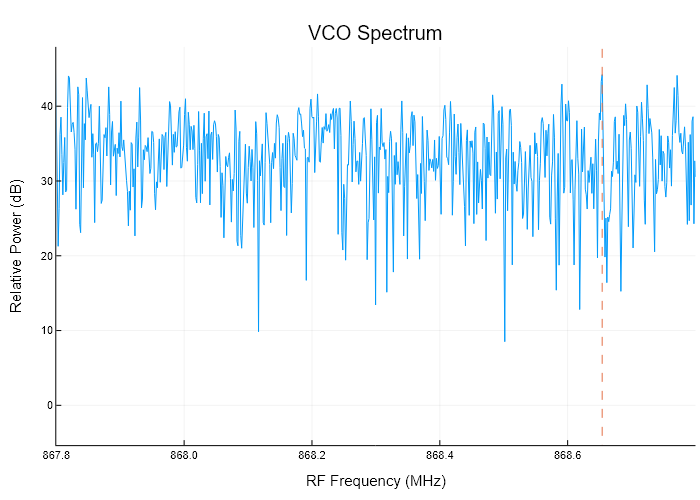

In [14]:
# ============================================================
# Cell 3 — Single VCO measurement
# ============================================================

# Read Pluto settings
fc = pyconvert(Float64, sdr.rx_lo)
fs = pyconvert(Float64, sdr.sample_rate)

# Discard one old capture
sdr.rx()

# Capture both RX channels
rx_data = sdr.rx()

# Use A1 / RX1 to detect the VCO
rx1 = pyconvert(Vector{ComplexF64}, rx_data[0])

# Detect VCO
f_vco, f_bb, freq, power =
    detect_vco(rx1, fc, fs)

println(
    "Detected VCO = ",
    round(f_vco / 1e6, digits=6),
    " MHz"
)

println(
    "Baseband frequency = ",
    round(f_bb / 1e3, digits=2),
    " kHz"
)

# Convert power to dB for plotting
power_db = 10 .* log10.(power .+ 1e-20)

plot(
    freq ./ 1e6,
    power_db,
    xlabel = "RF Frequency (MHz)",
    ylabel = "Relative Power (dB)",
    title = "VCO Spectrum",
    legend = false,
    xlim = (867.8, 868.8)
)

vline!(
    [f_vco / 1e6],
    linestyle = :dash
)

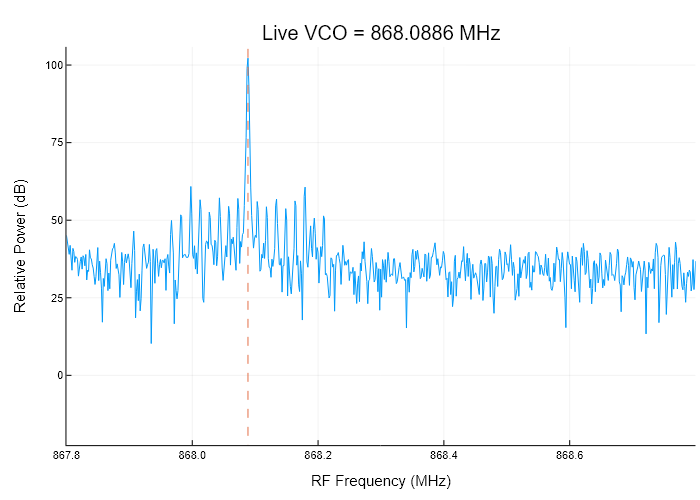

In [15]:
# ============================================================
# Cell 4 — Live VCO spectrum
# ============================================================

for k in 1:300

    # Read Pluto settings
    fc = pyconvert(Float64, sdr.rx_lo)
    fs = pyconvert(Float64, sdr.sample_rate)

    # Capture both channels
    rx_data = sdr.rx()

    # Use A1 / RX1
    rx1 = pyconvert(Vector{ComplexF64}, rx_data[0])

    # Detect VCO
    f_vco, f_bb, freq, power = detect_vco(rx1, fc, fs)

    power_db = 10 .* log10.(power .+ 1e-20)

    # Plot spectrum
    p = plot(
        freq ./ 1e6,
        power_db,
        xlabel = "RF Frequency (MHz)",
        ylabel = "Relative Power (dB)",
        title =
            "Live VCO = $(round(f_vco/1e6, digits=4)) MHz",
        legend = false,
        xlim = (867.8, 868.8)
    )

    vline!(
        p,
        [f_vco / 1e6],
        linestyle = :dash
    )

    IJulia.clear_output(true)
    display(p)

    sleep(0.2)
end

In [ ]:
# ============================================================
# Cell 5 — Measure all four relative phases
# ============================================================

phase_vector_deg = zeros(4)

fc = pyconvert(Float64, sdr.rx_lo)
fs = pyconvert(Float64, sdr.sample_rate)

for path in 1:4

    # Select switched antenna
    select_path(stm, path)

    # Give switch time to settle
    sleep(0.05)

    # Discard one old capture
    sdr.rx()

    # Simultaneous RX1 and RX2 capture
    rx_data = sdr.rx()

    rx1 = pyconvert(Vector{ComplexF64}, rx_data[0])
    rx2 = pyconvert(Vector{ComplexF64}, rx_data[1])

    # Remove DC
    rx1 .-= mean(rx1)
    rx2 .-= mean(rx2)

    # Detect VCO from reference antenna A1
    f_vco, f_bb, freq, power = detect_vco(rx1, fc, fs)

    N = length(rx1)
    n = 0:N-1

    # Hann window
    window = 0.5 .- 0.5 .* cos.(2π .* n ./ (N-1))

    # Complex reference tone
    reference_tone = exp.(-1im .* 2π .* f_bb .* n ./ fs)

    # Extract VCO tone
    V1 = sum(rx1 .* window .* reference_tone)
    Vn = sum(rx2 .* window .* reference_tone)

    # A1 - An phase
    phase_vector_deg[path] = angle(V1 * conj(Vn)) * 180 / π

    println(
        "A1 - A$(path + 1) = ",
        round(phase_vector_deg[path], digits=2),
        "°"
    )
end

println("\nMeasured phase vector:")
display(phase_vector_deg)

In [ ]:
# ============================================================
# Cell 6 — Repeated phase measurement at one angle
# ============================================================

num_measurements = 30

phase_measurements_deg = zeros(num_measurements, 4)

fc = pyconvert(Float64, sdr.rx_lo)
fs = pyconvert(Float64, sdr.sample_rate)

for measurement in 1:num_measurements

    for path in 1:4

        # Select A2, A3, A4 or A5
        select_path(stm, path)
        sleep(0.05)

        # Discard old samples
        sdr.rx()

        # Capture both Pluto channels
        rx_data = sdr.rx()

        rx1 =
            pyconvert(Vector{ComplexF64}, rx_data[0])

        rx2 =
            pyconvert(Vector{ComplexF64}, rx_data[1])

        # Remove DC
        rx1 .-= mean(rx1)
        rx2 .-= mean(rx2)

        # Find RF generator frequency
        f_vco, f_bb, freq, power = detect_vco(rx1, fc, fs)

        N = length(rx1)
        n = 0:N-1

        window = 0.5 .- 0.5 .* cos.(2π .* n ./ (N-1))

        reference_tone = exp.(-1im .* 2π .* f_bb .* n ./ fs)

        # Complex tone from both antennas
        V1 = sum(rx1 .* window .* reference_tone)

        Vn = sum(rx2 .* window .* reference_tone)

        # A1 - An
        phase_measurements_deg[measurement, path] = rad2deg(angle(V1 * conj(Vn)))
    end

    println("Measurement $measurement / $num_measurements")
end

In [ ]:
# ============================================================
# Mean phase vector at this angle
# ============================================================

mean_phase_deg = zeros(4)
phase_std_deg = zeros(4)

for path in 1:4

    phases = phase_measurements_deg[:, path]

    # Circular mean
    mean_phase_deg[path] = rad2deg(angle(mean(exp.(1im .* deg2rad.(phases)))))

    # Spread around circular mean
    residuals = rad2deg.(angle.(exp.(1im .* deg2rad.(phases .- mean_phase_deg[path]))))

    phase_std_deg[path] = std(residuals)
end

println("Mean phase vector:")
display(round.(mean_phase_deg, digits=2))

println("Phase standard deviation:")
display(round.(phase_std_deg, digits=2))

In [ ]:
# ============================================================
# Cell 7 — Measured calibration phase signatures
# ============================================================

cal_angles_deg =
    [0.0, 36.0, 72.0, 108.0, 144.0,
     180.0, 216.0, 252.0, 288.0, 324.0]

cal_measured_deg = [
     93.80    78.60  -151.35  -151.32
    135.01    11.41   101.82  -147.90
    111.13   -66.48   -21.15    93.48
     67.97  -123.98  -135.75   -50.06
    -14.17  -152.39   141.05  -146.81
    -76.17   -66.57   179.46   165.75
    -95.59    22.12  -117.05   168.15
    -97.32   101.87   -25.26  -120.52
    -58.96   129.63   146.56     7.42
     19.58   135.34  -111.32    93.74
]

display(cal_measured_deg)

In [ ]:
# ============================================================
# Cell 8 — Ideal UCA calibration phases
# ============================================================

c = 3e8
f0 = 868.1e6
λ = c / f0

Nant = 5
Rcircle = 0.09

# Antenna positions
A = zeros(Nant, 3)

for n in 1:Nant
    
    antenna_angle = 2π * (n - 1) / Nant
    A[n, 1] = Rcircle * cos(antenna_angle)
    A[n, 2] = Rcircle * sin(antenna_angle)
    A[n, 3] = 0
end

# Ideal phase values at calibration angles
cal_ideal_deg = zeros(length(cal_angles_deg), 4)

for i in 1:length(cal_angles_deg)

    theta = deg2rad(cal_angles_deg[i])

    u = [
        cos(theta),
        sin(theta),
        0
    ]

    for n in 2:Nant

        path_difference = dot(u, A[1, :] - A[n, :])

        phase = (2π / λ) * path_difference

        cal_ideal_deg[i, n - 1] = rad2deg(angle(exp(1im * phase)))
    end
end

display(round.(cal_ideal_deg, digits=2))

In [ ]:
# Wrap any phase to -180° ... +180°
wrap_deg(x) = rad2deg(angle(exp(1im * deg2rad(x))))

In [ ]:
# ============================================================
# Cell 9 — Calibration residuals
# ============================================================

cal_residual_deg = wrap_deg.(cal_measured_deg .- cal_ideal_deg)

display(round.(cal_residual_deg, digits=2))

In [ ]:
# ============================================================
# Cell 10 — Interpolate calibration residuals
# ============================================================

residual_lookup_deg = zeros(360, 4)

for theta in 0:359

    # Find the two measured calibration angles around theta
    lower_index = floor(Int, theta / 36) + 1
    upper_index = mod(lower_index, 10) + 1
    
    theta1 = cal_angles_deg[lower_index]
    
    theta2 = lower_index == 10 ? 360.0 : cal_angles_deg[upper_index]
    
    # Position between the two calibration angles
    fraction = (theta - theta1) / (theta2 - theta1)
    
    for path in 1:4

        residual1 = cal_residual_deg[lower_index, path]

        residual2 = cal_residual_deg[upper_index, path]

        # Shortest change around the phase circle
        residual_change = wrap_deg(residual2 - residual1)

        # Interpolated residual
        residual_lookup_deg[theta + 1, path] = wrap_deg(residual1 + fraction * residual_change)
    end
end

In [ ]:
# ============================================================
# Cell 11 — Calibrated phase lookup
# ============================================================

ideal_phase_lookup_deg = zeros(360, 4)

for theta_deg in 0:359

    theta = deg2rad(theta_deg)

    u = [
        cos(theta),
        sin(theta),
        0
    ]

    for n in 2:Nant

        path_difference = dot(u, A[1, :] - A[n, :])

        phase = (2π / λ) * path_difference

        ideal_phase_lookup_deg[theta_deg + 1, n - 1] = rad2deg(angle(exp(1im * phase)))
    end
end

# Add measured calibration correction
calibrated_phase_lookup_deg = wrap_deg.(ideal_phase_lookup_deg .+ residual_lookup_deg)

println(size(calibrated_phase_lookup_deg))


In [ ]:
# ============================================================
# Cell 12 — Check calibration anchors
# ============================================================

anchor_error_deg = zeros(10, 4)

for i in 1:length(cal_angles_deg)

    theta = Int(cal_angles_deg[i])

    measured_phase = cal_measured_deg[i, :]

    model_phase = calibrated_phase_lookup_deg[theta + 1, :]

    anchor_error_deg[i, :] = wrap_deg.(measured_phase .- model_phase)
end

display(round.(anchor_error_deg, digits=6))

println(
    "Maximum anchor error = ",
    maximum(abs.(anchor_error_deg)),
    "°"
)

In [ ]:
# ============================================================
# Cell 13 — Estimate direction of arrival
# ============================================================

function estimate_doa(measured_phase_deg)

    error_deg = zeros(360)

    for theta in 0:359

        model_phase = calibrated_phase_lookup_deg[theta + 1, :]

        phase_error = wrap_deg.(measured_phase_deg .- model_phase)

        error_deg[theta + 1] = sqrt(mean(phase_error.^2))
    end

    best_index = argmin(error_deg)

    estimated_angle_deg = best_index - 1

    minimum_error_deg = error_deg[best_index]

    return estimated_angle_deg, minimum_error_deg
end

In [ ]:
measured_phase_deg =
    [-75.07,
 -173.13,
  127.09,
  -30.88]

estimated_angle_deg, minimum_error_deg =
    estimate_doa(measured_phase_deg)

println("Estimated DoA = ", estimated_angle_deg, "°")
println(
    "Phase RMSE = ",
    round(minimum_error_deg, digits=2),
    "°"
)

In [ ]:
# Yesterday's 144° calibration vector
cal_144_deg = [-14.17, -152.39, 141.05, -146.81]

# Difference between today's measurement and yesterday's calibration
difference_deg =
    wrap_deg.(mean_phase_deg .- cal_144_deg)

println("Today's mean phase:")
display(round.(mean_phase_deg, digits=2))

println("Difference from yesterday:")
display(round.(difference_deg, digits=2))

## Optional Utility: VCO Source Characterisation

The VCO carrier frequency is not known exactly because it depends on the
tuning voltage. The Pluto is therefore swept across a wide frequency range
and the received spectrum is examined to locate the strongest RF carrier.

In [ ]:
# Frequency range to search for the VCO carrier

sweep_start = 650_000_000       # 650 MHz
sweep_stop  = 1_100_000_000     # 1100 MHz

sweep_sample_rate = 6_000_000   # 5 MS/s
sweep_bandwidth = 5_000_000     # 4 MHz
sweep_step = 5_000_000          # Move 4 MHz at a time

sweep_buffer_size = 4096

# Centre frequencies that the Pluto will visit during the sweep

sweep_frequencies = sweep_start : sweep_step : sweep_stop

In [ ]:
# Configure Pluto for the VCO frequency sweep

sweep_gain = 10.0     

pysetattr(sdr, "rx_enabled_channels", pylist([0]))
pysetattr(sdr, "sample_rate", sweep_sample_rate)
pysetattr(sdr, "rx_rf_bandwidth", sweep_bandwidth)
pysetattr(sdr, "rx_buffer_size", sweep_buffer_size)

pysetattr(sdr, "gain_control_mode_chan0", "manual")
pysetattr(sdr, "rx_hardwaregain_chan0", sweep_gain)

println("Sweep sample rate: ", sweep_sample_rate / 1e6, " MS/s")
println("Sweep bandwidth:   ", sweep_bandwidth / 1e6, " MHz")
println("Sweep RX gain:     ", sweep_gain, " dB")

In [ ]:
# Storage for the complete measured spectrum

all_frequencies = Float64[]
all_magnitudes = Float64[]


for centre_freq in sweep_frequencies
    
    # Tune Pluto to the next centre frequency
    pysetattr(sdr, "rx_lo", centre_freq)
    
    # Discard one capture after changing frequency
    # so that the next capture belongs to the new tuning position
    sdr.rx()
    
    # Capture IQ samples
    rx_data = sdr.rx()
    rx = pyconvert(Vector{ComplexF64}, rx_data)
    
    # Remove DC offset
    rx = rx .- mean(rx)
    
    # Calculate the spectrum
    N = length(rx)
    
    frequency_bins = -N÷2 : N÷2-1
    baseband_frequency = frequency_bins .* (sweep_sample_rate / N)
    
    spectrum = abs.(fftshift(fft(rx)))
    
    # Convert baseband frequency to actual RF frequency
    rf_frequency = centre_freq .+ baseband_frequency

    # Keep only the central 4 MHz of this capture
    keep = abs.(baseband_frequency) .<= sweep_bandwidth / 2

    append!(all_frequencies, rf_frequency[keep])
    append!(all_magnitudes, spectrum[keep])
end

println("Sweep complete")

In [ ]:
peak_index = argmax(all_magnitudes)

peak_frequency = all_frequencies[peak_index]
peak_magnitude = all_magnitudes[peak_index]

println("Strongest detected frequency: ", round(peak_frequency / 1e6, digits = 3), " MHz")

In [ ]:
# Plot the FFT magnitude across the complete sweep

plot(
    all_frequencies ./ 1e6,
    all_magnitudes,

    xlabel = "Frequency (MHz)",
    ylabel = "FFT Magnitude",
    title = "VCO Frequency Spectrum",

    legend = false,
    linewidth = 1
)

In [ ]:
# Restore the Pluto to the normal RDF receiver configuration
configure_rdf_receiver(sdr)